# Naive Bayes Classifier: Play Golf Dataset

This notebook follows the GeeksforGeeks article
[**Naive Bayes Classifiers**](https://www.geeksforgeeks.org/machine-learning/naive-bayes-classifiers/)
step by step, using the `golf.csv` dataset in this folder.

**Naive Bayes** is a probabilistic classification algorithm based on **Bayes' Theorem**. It is called *naive*
because it assumes every feature is **independent** of every other feature, given the class.

$$P(y \mid X) = \frac{P(X \mid y)\,P(y)}{P(X)}$$

| Term | Meaning |
|---|---|
| $P(y \mid X)$ | **Posterior**: probability of class $y$ given the features $X$ |
| $P(X \mid y)$ | **Likelihood**: probability of the features $X$ given class $y$ |
| $P(y)$ | **Prior**: probability of class $y$ |
| $P(X)$ | **Evidence**: marginal probability of the features |

**Contents**
1. Load and inspect the data
2. Exploratory data analysis
3. Feature matrix & response vector
4. Prior probabilities $P(y)$
5. Conditional probability tables $P(x_i \mid y)$ (Tables 1 to 4)
6. Worked example: predicting *today* by hand
7. Naive Bayes classifier from scratch
8. The zero-frequency problem & Laplace smoothing
9. Comparison with scikit-learn `CategoricalNB`
10. Evaluation (training accuracy & leave-one-out CV)
11. Bonus: Gaussian Naive Bayes for continuous features
12. Advantages, disadvantages & applications

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import LeaveOneOut, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.datasets import load_iris

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

## 1. Load and inspect the data

The raw file wraps every value in single quotes and has stray spaces after some commas
(e.g. `'High', 'Weak'`), so we tell pandas to use `'` as the quote character, skip the
initial spaces, and then strip any remaining whitespace.

In [2]:
df = pd.read_csv("golf.csv", quotechar="'", skipinitialspace=True)

# Clean column names and string values (removes leftover spaces / quotes)
df.columns = df.columns.str.strip()
df = df.apply(lambda col: col.str.strip().str.strip("'"))

# Friendlier column names, matching the article
df = df.rename(columns={"outlook": "Outlook", "temp": "Temperature",
                        "humidity": "Humidity", "wind": "Wind", "label": "Play"})
df

,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [3]:
print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isna().sum(), sep="")
print("\nUnique values per feature:")
for col in df.columns:
    print(f"  {col:<12} -> {sorted(df[col].unique())}")

Shape: (14, 5)

Missing values per column:
Outlook        0
Temperature    0
Humidity       0
Wind           0
Play           0
dtype: int64

Unique values per feature:
  Outlook      -> ['Overcast', 'Rain', 'Sunny']
  Temperature  -> ['Cool', 'Hot', 'Mild']
  Humidity     -> ['High', 'Normal']
  Wind         -> ['Strong', 'Weak']
  Play         -> ['No', 'Yes']


> **Note:** This dataset is the same one used in the article. The article writes *Windy = False / True*;
> in our CSV the same information is stored as *Wind = Weak / Strong* (`False` → `Weak`, `True` → `Strong`).

## 2. Exploratory data analysis

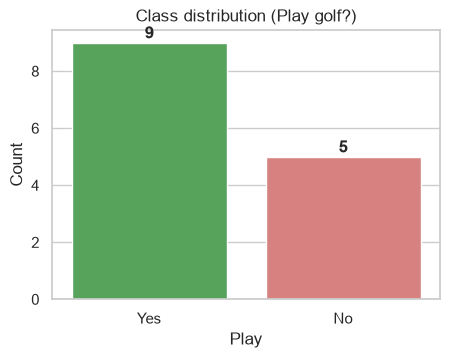

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = df["Play"].value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette={"Yes": "#4CAF50", "No": "#E57373"}, legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.15, str(v), ha="center", fontweight="bold")
ax.set(title="Class distribution (Play golf?)", xlabel="Play", ylabel="Count")
plt.show()

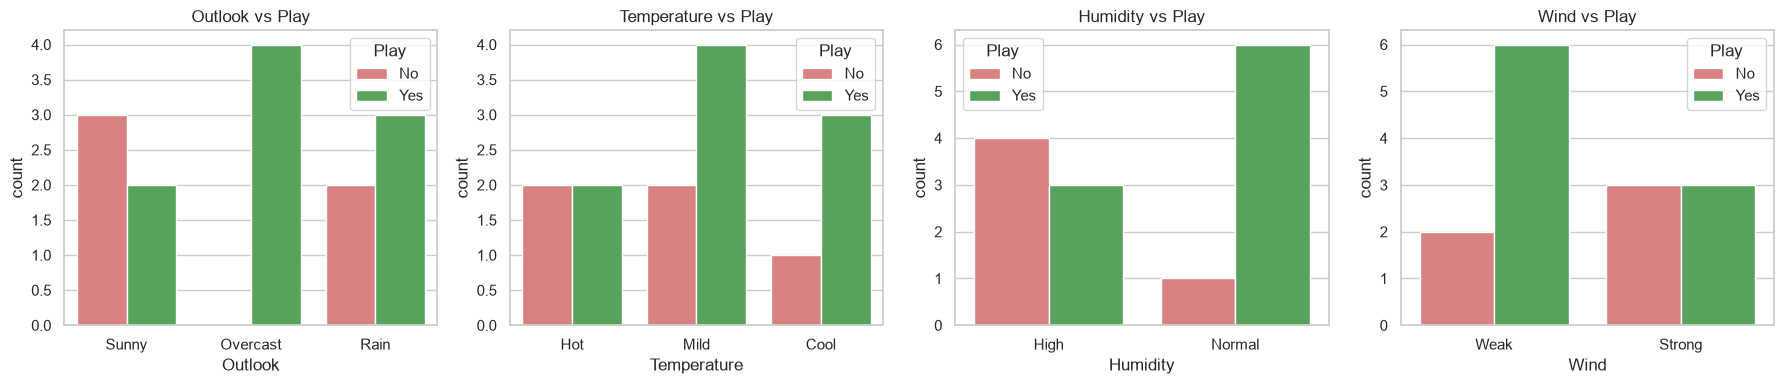

In [5]:
features = ["Outlook", "Temperature", "Humidity", "Wind"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, feat in zip(axes, features):
    sns.countplot(data=df, x=feat, hue="Play", palette={"Yes": "#4CAF50", "No": "#E57373"}, ax=ax)
    ax.set_title(f"{feat} vs Play")
plt.tight_layout()
plt.show()

## 3. Feature matrix & response vector

As in the article, the dataset is split into:
* **Feature matrix `X`**: the independent features *Outlook, Temperature, Humidity, Wind*
* **Response vector `y`**: the class variable *Play* (`Yes` / `No`)

In [6]:
X = df[features]
y = df["Play"]
print("X shape:", X.shape, "| y shape:", y.shape)
X.head()

X shape: (14, 4) | y shape: (14,)


,Outlook,Temperature,Humidity,Wind
0,Sunny,Hot,High,Weak
1,Sunny,Hot,High,Strong
2,Overcast,Hot,High,Weak
3,Rain,Mild,High,Weak
4,Rain,Cool,Normal,Weak


## 4. Prior probabilities $P(y)$

From the 14 rows in the dataset:
$$P(\text{Yes}) = \frac{9}{14} \qquad P(\text{No}) = \frac{5}{14}$$

In [7]:
class_counts = y.value_counts()
priors = class_counts / len(y)

pd.DataFrame({"Count": class_counts,
              "Fraction": [f"{c}/{len(y)}" for c in class_counts],
              "P(y)": priors})

,Count,Fraction,P(y)
Play,,,
Yes,9,9/14,0.6429
No,5,5/14,0.3571


## 5. Conditional probability tables $P(x_i \mid y)$ (Tables 1 to 4)

For each feature we count how often each value occurs within each class and divide by the class count.
For example $P(\text{Sunny} \mid \text{Yes}) = \dfrac{\#(\text{Sunny and Yes})}{\#\text{Yes}} = \dfrac{2}{9}$.

In [8]:
likelihood_tables = {}
for feat in features:
    freq = pd.crosstab(df[feat], df["Play"])                 # frequency table
    prob = freq / freq.sum(axis=0)                           # P(feature value | class)
    likelihood_tables[feat] = prob

    frac = freq.apply(lambda c: [f"{v}/{c.sum()}" for v in c])  # nicer fraction view
    table = pd.concat({"Frequency": freq, "P(x|y) fraction": frac, "P(x|y)": prob.round(3)}, axis=1)
    print(f"\nTable: {feat}")
    display(table)


Table: Outlook


Frequency     P(x|y) fraction      P(x|y)       
Play            No Yes              No  Yes     No    Yes
Outlook                                                  
Overcast         0   4             0/5  4/9    0.0  0.444
Rain             2   3             2/5  3/9    0.4  0.333
Sunny            3   2             3/5  2/9    0.6  0.222


Table: Temperature


Frequency     P(x|y) fraction      P(x|y)       
Play               No Yes              No  Yes     No    Yes
Temperature                                                 
Cool                1   3             1/5  3/9    0.2  0.333
Hot                 2   2             2/5  2/9    0.4  0.222
Mild                2   4             2/5  4/9    0.4  0.444


Table: Humidity


Frequency     P(x|y) fraction      P(x|y)       
Play            No Yes              No  Yes     No    Yes
Humidity                                                 
High             4   3             4/5  3/9    0.8  0.333
Normal           1   6             1/5  6/9    0.2  0.667


Table: Wind


Frequency     P(x|y) fraction      P(x|y)       
Play          No Yes              No  Yes     No    Yes
Wind                                                   
Strong         3   3             3/5  3/9    0.6  0.333
Weak           2   6             2/5  6/9    0.4  0.667

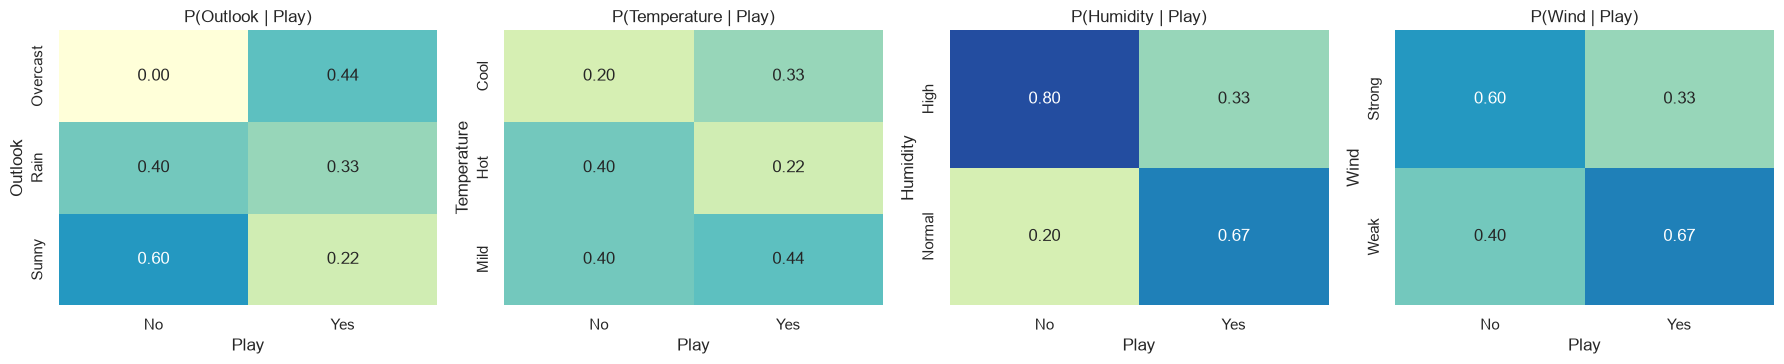

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, feat in zip(axes, features):
    sns.heatmap(likelihood_tables[feat], annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(f"P({feat} | Play)")
plt.tight_layout()
plt.show()

## 6. Worked example: predicting *today* by hand

Article example: $X_{today} = (\text{Sunny}, \text{Hot}, \text{Normal}, \text{False})$ → in our CSV *Wind = Weak*.

Using the naive (conditional independence) assumption:
$$P(y \mid x_1,\dots,x_n) \propto P(y)\prod_{i=1}^{n} P(x_i \mid y)
\qquad\Rightarrow\qquad \hat{y} = \arg\max_y \; P(y)\prod_{i=1}^{n} P(x_i \mid y)$$

**For Yes:** $\;\frac{2}{9}\cdot\frac{2}{9}\cdot\frac{6}{9}\cdot\frac{6}{9}\cdot\frac{9}{14} \approx 0.01411$

**For No:** $\;\frac{3}{5}\cdot\frac{2}{5}\cdot\frac{1}{5}\cdot\frac{2}{5}\cdot\frac{5}{14} \approx 0.00686$

In [10]:
today = {"Outlook": "Sunny", "Temperature": "Hot", "Humidity": "Normal", "Wind": "Weak"}

unnormalized = {}
for cls in priors.index:
    terms = [likelihood_tables[f].loc[today[f], cls] for f in features]
    score = priors[cls] * np.prod(terms)
    unnormalized[cls] = score
    steps = " * ".join(f"{t:.4f}" for t in terms)
    print(f"P({cls:>3} | today) ∝ {steps} * {priors[cls]:.4f} = {score:.5f}")

P(Yes | today) ∝ 0.2222 * 0.2222 * 0.6667 * 0.6667 * 0.6429 = 0.01411
P( No | today) ∝ 0.6000 * 0.4000 * 0.2000 * 0.4000 * 0.3571 = 0.00686


### Normalize the probabilities

$$P(\text{Yes} \mid today) = \frac{0.01411}{0.01411 + 0.00686} \approx 0.673
\qquad
P(\text{No} \mid today) = \frac{0.00686}{0.01411 + 0.00686} \approx 0.327$$

P(Yes | today) = 0.673
P( No | today) = 0.327

Final prediction -> Yes (Play golf)


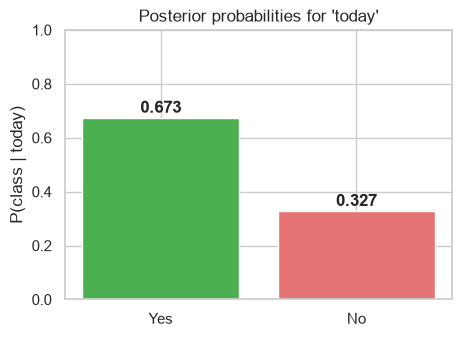

In [11]:
total = sum(unnormalized.values())
posterior = {cls: s / total for cls, s in unnormalized.items()}
for cls, p in posterior.items():
    print(f"P({cls:>3} | today) = {p:.3f}")

prediction = max(posterior, key=posterior.get)
print(f"\nFinal prediction -> {prediction} ({'Play golf' if prediction == 'Yes' else 'Do not play golf'})")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(posterior.keys(), posterior.values(), color=["#4CAF50" if c == "Yes" else "#E57373" for c in posterior])
for i, v in enumerate(posterior.values()):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
ax.set(ylim=(0, 1), title="Posterior probabilities for 'today'", ylabel="P(class | today)")
plt.show()

## 7. Naive Bayes classifier from scratch

Now we wrap the steps above into a reusable class:

* `fit`: learns the priors $P(y)$ and the likelihoods $P(x_i \mid y)$ by counting
* `predict_proba`: computes $P(y)\prod_i P(x_i \mid y)$ for each class and normalizes
* `predict`: returns the class with the highest posterior

An optional **Laplace smoothing** parameter `alpha` is included (explained in Section 8):
$$P(x_i = v \mid y) = \frac{\text{count}(x_i = v,\, y) + \alpha}{\text{count}(y) + \alpha \cdot K_i}$$
where $K_i$ is the number of distinct values of feature $i$. With `alpha=0` we get exactly the article's numbers.

In [12]:
class NaiveBayesClassifier:
    # Categorical Naive Bayes implemented with plain counting.

    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def fit(self, X, y, categories=None):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = pd.Series(y).reset_index(drop=True)
        self.features_ = list(X.columns)
        self.classes_ = np.array(sorted(y.unique()))
        # all possible values for each feature (K_i); can be supplied so unseen values are handled
        self.categories_ = categories or {f: sorted(X[f].unique()) for f in self.features_}

        self.class_count_ = y.value_counts().reindex(self.classes_)
        self.priors_ = self.class_count_ / len(y)

        self.likelihoods_ = {}
        for f in self.features_:
            counts = (pd.crosstab(X[f], y)
                        .reindex(index=self.categories_[f], columns=self.classes_, fill_value=0))
            k = len(self.categories_[f])
            self.likelihoods_[f] = (counts + self.alpha) / (self.class_count_ + self.alpha * k)
        return self

    def predict_proba(self, X):
        X = pd.DataFrame(X)
        # P(y) * prod_i P(x_i | y) for every row and class; unseen value -> 0
        joint = pd.DataFrame(self.priors_.to_dict(), index=X.index)
        for f in self.features_:
            joint *= self.likelihoods_[f].reindex(X[f]).fillna(0.0).to_numpy()
        totals = joint.sum(axis=1).replace(0, np.nan)          # avoid 0/0
        return joint.div(totals, axis=0).fillna(1 / len(self.classes_))

    def predict(self, X):
        return self.predict_proba(X).idxmax(axis=1).to_numpy()

In [13]:
nb = NaiveBayesClassifier(alpha=0).fit(X, y)

today_df = pd.DataFrame([today])
print("Posterior for today:")
display(nb.predict_proba(today_df))
print("Prediction:", nb.predict(today_df)[0])

Posterior for today:


Play,No,Yes
0,0.3271,0.6729


Prediction: Yes


### Predicting a few new days

In [14]:
new_days = pd.DataFrame([
    {"Outlook": "Sunny",    "Temperature": "Hot",  "Humidity": "Normal", "Wind": "Weak"},    # article example
    {"Outlook": "Rain",     "Temperature": "Cool", "Humidity": "High",   "Wind": "Strong"},
    {"Outlook": "Overcast", "Temperature": "Mild", "Humidity": "High",   "Wind": "Weak"},
    {"Outlook": "Sunny",    "Temperature": "Mild", "Humidity": "High",   "Wind": "Strong"},
])
result = new_days.copy()
result[["P(No)", "P(Yes)"]] = nb.predict_proba(new_days)[["No", "Yes"]].to_numpy()
result["Prediction"] = nb.predict(new_days)
result

,Outlook,Temperature,Humidity,Wind,P(No),P(Yes),Prediction
0,Sunny,Hot,Normal,Weak,0.3271,0.6729,Yes
1,Rain,Cool,High,Strong,0.6334,0.3666,No
2,Overcast,Mild,High,Weak,0.0000,1.0000,Yes
3,Sunny,Mild,High,Strong,0.8536,0.1464,No


## 8. The zero-frequency problem & Laplace smoothing

One disadvantage listed in the article: Naive Bayes *"may assign zero probability to unseen events"*.

In our data, **Overcast never occurs with `No`**, so $P(\text{Overcast} \mid \text{No}) = 0/5 = 0$.
Any day with *Outlook = Overcast* then gets $P(\text{No} \mid X) = 0$, no matter how strongly the other
features point to `No`. **Laplace (add-α) smoothing** fixes this by adding a small pseudo-count `alpha`
to every count.

In [15]:
print("P(Outlook | Play) without smoothing (alpha=0):")
display(nb.likelihoods_["Outlook"])

nb_smooth = NaiveBayesClassifier(alpha=1).fit(X, y)
print("P(Outlook | Play) with Laplace smoothing (alpha=1):")
display(nb_smooth.likelihoods_["Outlook"])

P(Outlook | Play) without smoothing (alpha=0):


Play,No,Yes
Outlook,,
Overcast,0.0,0.4444
Rain,0.4,0.3333
Sunny,0.6,0.2222


P(Outlook | Play) with Laplace smoothing (alpha=1):


Play,No,Yes
Outlook,,
Overcast,0.125,0.4167
Rain,0.375,0.3333
Sunny,0.500,0.2500


In [16]:
# A day where every feature except Outlook points towards "No"
tricky_day = pd.DataFrame([{"Outlook": "Overcast", "Temperature": "Hot", "Humidity": "High", "Wind": "Strong"}])

comparison = pd.DataFrame({
    "alpha = 0 (no smoothing)": nb.predict_proba(tricky_day).iloc[0],
    "alpha = 1 (Laplace)":      nb_smooth.predict_proba(tricky_day).iloc[0],
}).T
comparison

Play,No,Yes
alpha = 0 (no smoothing),0.0000,1.0000
alpha = 1 (Laplace),0.4356,0.5644


## 9. Comparison with scikit-learn `CategoricalNB`

scikit-learn's `CategoricalNB` implements exactly this model for categorical features.
It needs numeric input, so we first encode the categories with an `OrdinalEncoder`.
We verify that it reproduces our from-scratch probabilities.

In [17]:
encoder = OrdinalEncoder()
X_enc = encoder.fit_transform(X)
n_categories = [len(c) for c in encoder.categories_]

for alpha in [1e-10, 1.0]:      # ~0 (article) and Laplace smoothing
    sk_nb = CategoricalNB(alpha=alpha, force_alpha=True, min_categories=n_categories).fit(X_enc, y)
    ours = NaiveBayesClassifier(alpha=alpha).fit(X, y)

    sk_proba = sk_nb.predict_proba(encoder.transform(new_days))
    our_proba = ours.predict_proba(new_days)[sk_nb.classes_].to_numpy()

    print(f"alpha = {alpha:g}")
    print("  scikit-learn P(Yes):", np.round(sk_proba[:, 1], 4))
    print("  from scratch P(Yes):", np.round(our_proba[:, 1], 4))
    print("  identical:", np.allclose(sk_proba, our_proba, atol=1e-6), "\n")

alpha = 1e-10
  scikit-learn P(Yes): [0.6729 0.3666 1.     0.1464]
  from scratch P(Yes): [0.6729 0.3666 1.     0.1464]
  identical: True 

alpha = 1
  scikit-learn P(Yes): [0.6649 0.4087 0.8344 0.2447]
  from scratch P(Yes): [0.6649 0.4087 0.8344 0.2447]
  identical: True 



## 10. Evaluation

### 10.1 Training accuracy
With only 14 rows we first check how well the model fits the data it was trained on.

Training accuracy (alpha=0): 92.86%



              precision    recall  f1-score   support

          No       1.00      0.80      0.89         5
         Yes       0.90      1.00      0.95         9

    accuracy                           0.93        14
   macro avg       0.95      0.90      0.92        14
weighted avg       0.94      0.93      0.93        14



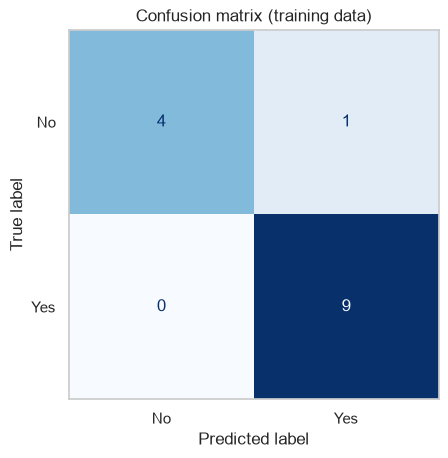

In [18]:
y_pred_train = nb.predict(X)
print(f"Training accuracy (alpha=0): {accuracy_score(y, y_pred_train):.2%}\n")
print(classification_report(y, y_pred_train, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y, y_pred_train, labels=["No", "Yes"]),
                       display_labels=["No", "Yes"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix (training data)")
plt.grid(False)
plt.show()

### 10.2 Leave-one-out cross-validation

The dataset is far too small for a normal train/test split, so we use **leave-one-out CV (LOOCV)**:
train on 13 rows, predict the 1 held-out row, repeat 14 times. We compare `alpha=0` and `alpha=1`;
smoothing guards against zero probabilities when a held-out row contains a value never seen with a class
in the other 13 rows.

In [19]:
all_categories = {f: sorted(X[f].unique()) for f in features}

results = {}
for alpha in [0, 1]:
    preds = []
    for train_idx, test_idx in LeaveOneOut().split(X):
        model = NaiveBayesClassifier(alpha=alpha).fit(X.iloc[train_idx], y.iloc[train_idx], categories=all_categories)
        preds.append(model.predict(X.iloc[test_idx])[0])
    results[alpha] = np.array(preds)
    print(f"LOOCV accuracy (from scratch, alpha={alpha}): {accuracy_score(y, preds):.2%}")

# Same thing with scikit-learn
sk_loo = cross_val_predict(CategoricalNB(alpha=1, force_alpha=True, min_categories=n_categories), X_enc, y, cv=LeaveOneOut())
print(f"LOOCV accuracy (scikit-learn, alpha=1):  {accuracy_score(y, sk_loo):.2%}")
print("From-scratch and scikit-learn LOOCV predictions agree:", (results[1] == sk_loo).all())

LOOCV accuracy (from scratch, alpha=0): 57.14%
LOOCV accuracy (from scratch, alpha=1): 50.00%


LOOCV accuracy (scikit-learn, alpha=1):  50.00%
From-scratch and scikit-learn LOOCV predictions agree: True


In [20]:
loo_table = df.copy()
loo_table["LOOCV prediction"] = results[1]
loo_table["Correct"] = np.where(loo_table["Play"] == loo_table["LOOCV prediction"], "✔", "✘")
loo_table

,Outlook,Temperature,Humidity,Wind,Play,LOOCV prediction,Correct
0,Sunny,Hot,High,Weak,No,Yes,✘
1,Sunny,Hot,High,Strong,No,No,✔
2,Overcast,Hot,High,Weak,Yes,Yes,✔
3,Rain,Mild,High,Weak,Yes,No,✘
4,Rain,Cool,Normal,Weak,Yes,Yes,✔
5,Rain,Cool,Normal,Strong,No,Yes,✘
6,Overcast,Cool,Normal,Strong,Yes,Yes,✔
7,Sunny,Mild,High,Weak,No,Yes,✘
8,Sunny,Cool,Normal,Weak,Yes,Yes,✔
9,Rain,Mild,Normal,Weak,Yes,Yes,✔


**Interpretation.** Training accuracy is high (~93%), but LOOCV accuracy is only around 50% to 57%.
With just 14 rows, removing a single row noticeably changes the probability tables, and several rows
(e.g. *Sunny, Mild, Normal, Strong → Yes*) contradict the overall trends. So the estimate is very noisy, and
the gap shows high variance: the model fits noise in this small dataset instead of generalising.
That's expected for a teaching example: the point of this dataset is to show *how* Naive Bayes computes
its probabilities, not to build a production model. With more data, the probability estimates (and the accuracy)
become much more reliable.

## 11. Bonus: Gaussian Naive Bayes for continuous features

The golf dataset only has categorical features, but the article also covers **continuous** features.
For those, each feature is assumed to follow a **Gaussian (normal) distribution** within each class:

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma^2_y}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma^2_y}\right)$$

where $\mu_y$ and $\sigma^2_y$ are the mean and variance of feature $x_i$ in class $y$.
We demonstrate it on the classic **Iris** dataset (bundled with scikit-learn), implementing the formula
from scratch and comparing with `GaussianNB`.

In [21]:
iris = load_iris()
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    iris.data, iris.target, test_size=0.4, random_state=1, stratify=iris.target)


class GaussianNaiveBayes:
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.priors_ = np.array([np.mean(y == c) for c in self.classes_])
        self.mu_ = np.array([X[y == c].mean(axis=0) for c in self.classes_])
        self.var_ = np.array([X[y == c].var(axis=0) for c in self.classes_]) + 1e-9
        return self

    def predict_proba(self, X):
        # log P(y) + sum_i log N(x_i | mu_y, sigma_y^2)   (logs avoid numeric underflow)
        log_lik = -0.5 * (np.log(2 * np.pi * self.var_)[None] + (X[:, None, :] - self.mu_[None]) ** 2 / self.var_[None])
        log_post = np.log(self.priors_) + log_lik.sum(axis=2)
        log_post -= log_post.max(axis=1, keepdims=True)
        post = np.exp(log_post)
        return post / post.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


gnb_scratch = GaussianNaiveBayes().fit(Xi_train, yi_train)
gnb_sklearn = GaussianNB().fit(Xi_train, yi_train)

print(f"Gaussian NB accuracy (from scratch):  {accuracy_score(yi_test, gnb_scratch.predict(Xi_test)):.2%}")
print(f"Gaussian NB accuracy (scikit-learn):  {accuracy_score(yi_test, gnb_sklearn.predict(Xi_test)):.2%}")

Gaussian NB accuracy (from scratch):  98.33%
Gaussian NB accuracy (scikit-learn):  98.33%


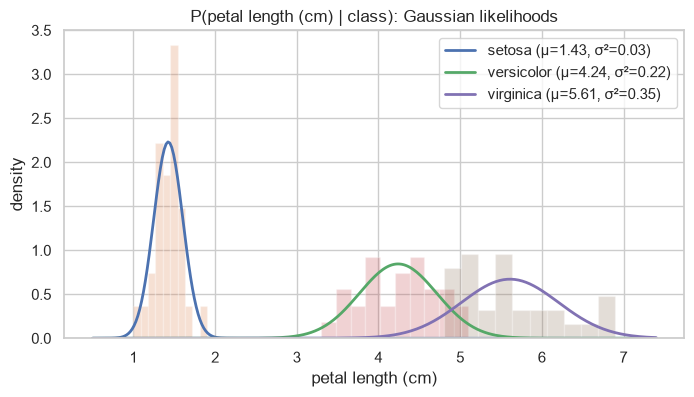

In [22]:
# Visualise the per-class Gaussians learned for one feature (petal length)
feat_idx = 2
xs = np.linspace(iris.data[:, feat_idx].min() - 0.5, iris.data[:, feat_idx].max() + 0.5, 300)

fig, ax = plt.subplots(figsize=(8, 4))
for c, name in enumerate(iris.target_names):
    mu, var = gnb_scratch.mu_[c, feat_idx], gnb_scratch.var_[c, feat_idx]
    pdf = np.exp(-(xs - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
    ax.plot(xs, pdf, lw=2, label=f"{name} (μ={mu:.2f}, σ²={var:.2f})")
    ax.hist(Xi_train[yi_train == c, feat_idx], bins=10, density=True, alpha=0.25)
ax.set(title=f"P({iris.feature_names[feat_idx]} | class): Gaussian likelihoods",
       xlabel=iris.feature_names[feat_idx], ylabel="density")
ax.legend()
plt.show()

## 12. Advantages, disadvantages & applications

**Types of Naive Bayes**
* **Gaussian NB**: continuous features assumed normally distributed (Section 11)
* **Multinomial NB**: features are counts/frequencies (e.g. word counts in text)
* **Bernoulli NB**: binary features (e.g. word present / absent)
* *(Categorical NB: categorical features like our golf data, Sections 5 to 10)*

**Advantages**
* Easy to implement and computationally efficient, since training is just counting.
* Effective with a large number of features.
* Performs well even with limited training data (we trained on only 14 rows!).
* Handles categorical features naturally.

**Disadvantages**
* Assumes features are independent, which rarely holds exactly in real data.
* Can be influenced by irrelevant attributes.
* May assign zero probability to unseen events (Section 8), mitigated with Laplace smoothing.

**Applications:** spam filtering, text classification / sentiment analysis, medical diagnosis,
credit scoring and weather prediction.

### Summary
For the article's example day *(Sunny, Hot, Normal, Weak wind)* both the hand calculation and the classifier give
$P(\text{Yes} \mid today) \approx 0.673$ and $P(\text{No} \mid today) \approx 0.327$, so the model predicts
**Yes, play golf**. Our from-scratch implementation matches scikit-learn's `CategoricalNB` exactly.